In [54]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from skimage.feature import local_binary_pattern
import skimage.feature as feature

import warnings
import mahotas
warnings.filterwarnings("ignore")

In [55]:
GROUP = "C1"
DTYPE="HSV"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C1_10,27,"[DATA/TRAINING/C1/C1_10/IMG_6497.HEIC, DATA/TR..."
1,C1_11,26,"[DATA/TRAINING/C1/C1_11/IMG_6665.HEIC, DATA/TR..."
2,C1_12,27,"[DATA/TRAINING/C1/C1_12/IMG_6797.HEIC, DATA/TR..."
3,C1_13,27,"[DATA/TRAINING/C1/C1_13/IMG_6929.HEIC, DATA/TR..."
4,C1_14,26,"[DATA/TRAINING/C1/C1_14/IMG_7188.HEIC, DATA/TR..."
5,C1_15,28,"[DATA/TRAINING/C1/C1_15/IMG_7316.HEIC, DATA/TR..."
6,C1_16,27,"[DATA/TRAINING/C1/C1_16/IMG_7446.HEIC, DATA/TR..."


In [56]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [57]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [58]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

In [59]:
def read_image(pic_path):
    ext = pic_path.split(".")[1]
    if ext=="HEIC":
        return read_imgHEIC(pic_path)
    else:
        img=cv2.imread(pic_path)
        return img

In [60]:
def hsv_histogram(image, bins):
    #print(mask)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    #The 3D color histogram is extracted from the mask area of the image using the bin number of each channel provided
    hist = cv2.calcHist([image], [0, 1, 2], None, [bins, bins, bins], [0, 180, 0, 256, 0, 256])
    hist = cv2.normalize(hist, hist).flatten()
    #Return histogram
    return hist

Text(0.5, 1.0, '16% IMG_7481.HEIC')

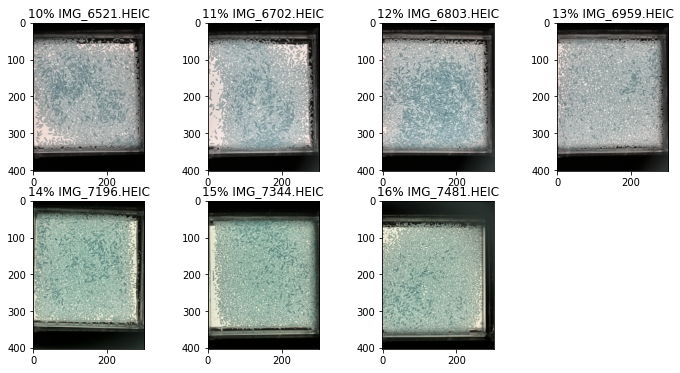

In [250]:
fig=plt.figure(figsize=(12, 6)) 
ax1 = fig.add_subplot(2,4,1); path_image= random.randint(0, 25)
image = read_image(data_path[0][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10% " + data_path[0][path_image].split("/")[4])
ax2 = fig.add_subplot(2,4,2); path_image= random.randint(0, 25)
image = read_image(data_path[1][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11% "+ data_path[1][path_image].split("/")[4])
ax3 = fig.add_subplot(2,4,3); path_image= random.randint(0, 25)
image = read_image(data_path[2][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12% "+ data_path[2][path_image].split("/")[4])
ax4 = fig.add_subplot(2,4,4); path_image= random.randint(0, 25)
image = read_image(data_path[3][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13% "+ data_path[3][path_image].split("/")[4])
ax5 = fig.add_subplot(2,4,5); path_image= random.randint(0, 25)
image = read_image(data_path[4][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14% "+ data_path[4][path_image].split("/")[4])
ax6 = fig.add_subplot(2,4,6); path_image= random.randint(0, 25)
image = read_image(data_path[5][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15% "+ data_path[5][path_image].split("/")[4])
ax7 = fig.add_subplot(2,4,7); path_image= random.randint(0, 25)
image = read_image(data_path[6][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16% "+ data_path[6][path_image].split("/")[4])

In [219]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
scale=25
bins=16
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        
        arr_img_hist.append(hsv_histogram(image, bins))
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["bins"] = bins
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [220]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,4093,4094,4095,scale,bins,height,width,channels,IMAGENAME,HUMIDITY
0,0.085356,0.039642,0.012461,0.012223,0.006663,0.003221,0.002321,0.004007,0.007166,0.011808,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6497.HEIC,10
1,0.055334,0.077516,0.009247,0.011183,0.007080,0.003679,0.001936,0.001512,0.004757,0.013598,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6498.HEIC,10
2,0.168518,0.045408,0.012025,0.006584,0.004897,0.004045,0.003120,0.002313,0.002721,0.008525,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6499.HEIC,10
3,0.238255,0.059552,0.010201,0.008549,0.006190,0.003350,0.003086,0.001359,0.003501,0.008408,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6500.HEIC,10
4,0.146265,0.043339,0.013797,0.004767,0.007338,0.005233,0.004437,0.003211,0.004273,0.011455,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6501.HEIC,10
5,0.085137,0.030939,0.008790,0.009140,0.006656,0.005168,0.005101,0.003783,0.006049,0.018556,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6502.HEIC,10
6,0.097405,0.048983,0.010799,0.007246,0.003768,0.001711,0.002244,0.001907,0.002375,0.011911,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6503.HEIC,10
7,0.133964,0.059702,0.011769,0.007855,0.003453,0.002514,0.002873,0.001971,0.002486,0.009052,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6504.HEIC,10
8,0.122682,0.038639,0.011661,0.005672,0.003753,0.002342,0.001900,0.001459,0.003829,0.010020,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6505.HEIC,10
9,0.116725,0.037109,0.010541,0.003393,0.001789,0.001134,0.001095,0.000636,0.001936,0.008625,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6506.HEIC,10


# Classification

In [221]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-7]
#X

In [222]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [223]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [224]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [225]:
TYPE="CV"

In [226]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [227]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["bins"]=bins; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,bins,height,width,channels
0,1,0.736842,0.811905,0.714286,0.759973,HSV,C1,RF_C,25,16,1008,756,3
1,2,0.789474,0.821429,0.809524,0.815433,HSV,C1,RF_C,25,16,1008,756,3
2,3,0.736842,0.752381,0.714286,0.732839,HSV,C1,RF_C,25,16,1008,756,3
3,4,0.947368,0.964286,0.952381,0.958296,HSV,C1,RF_C,25,16,1008,756,3
4,5,0.947368,0.964286,0.952381,0.958296,HSV,C1,RF_C,25,16,1008,756,3
5,6,0.789474,0.821429,0.785714,0.803175,HSV,C1,RF_C,25,16,1008,756,3
6,7,0.947368,0.952381,0.952381,0.952381,HSV,C1,RF_C,25,16,1008,756,3
7,8,0.947368,0.952381,0.952381,0.952381,HSV,C1,RF_C,25,16,1008,756,3
8,9,0.777778,0.833333,0.809524,0.821256,HSV,C1,RF_C,25,16,1008,756,3
9,10,0.888889,0.928571,0.904762,0.916512,HSV,C1,RF_C,25,16,1008,756,3


In [228]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,HSV,C1,RF_C,0.850877,0.854762,0.867054,0.880238


### MLP Classifier

In [229]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [230]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [231]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["bins"]=bins; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,bins,height,width,channels
0,1,0.842105,0.880952,0.857143,0.868885,HSV,C1,MLP_C,25,16,1008,756,3
1,2,0.842105,0.880952,0.857143,0.868885,HSV,C1,MLP_C,25,16,1008,756,3
2,3,0.894737,0.928571,0.904762,0.916512,HSV,C1,MLP_C,25,16,1008,756,3
3,4,0.894737,0.928571,0.904762,0.916512,HSV,C1,MLP_C,25,16,1008,756,3
4,5,0.842105,0.871429,0.833333,0.851955,HSV,C1,MLP_C,25,16,1008,756,3
5,6,0.894737,0.916667,0.880952,0.898455,HSV,C1,MLP_C,25,16,1008,756,3
6,7,0.947368,0.952381,0.952381,0.952381,HSV,C1,MLP_C,25,16,1008,756,3
7,8,0.894737,0.928571,0.857143,0.891429,HSV,C1,MLP_C,25,16,1008,756,3
8,9,0.833333,0.907143,0.809524,0.855558,HSV,C1,MLP_C,25,16,1008,756,3
9,10,0.944444,0.964286,0.952381,0.958296,HSV,C1,MLP_C,25,16,1008,756,3


In [232]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,HSV,C1,MLP_C,0.883041,0.880952,0.897887,0.915952


### XGBoost Classifier

In [233]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [234]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["bins"]=bins; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,bins,height,width,channels
0,1,0.842105,0.892857,0.833333,0.862069,HSV,C1,XGB_C,25,16,1008,756,3
1,2,0.789474,0.785714,0.785714,0.785714,HSV,C1,XGB_C,25,16,1008,756,3
2,3,0.842105,0.845238,0.833333,0.839243,HSV,C1,XGB_C,25,16,1008,756,3
3,4,0.947368,0.964286,0.928571,0.946092,HSV,C1,XGB_C,25,16,1008,756,3
4,5,0.894737,0.928571,0.880952,0.904135,HSV,C1,XGB_C,25,16,1008,756,3
5,6,1.000000,1.000000,1.000000,1.000000,HSV,C1,XGB_C,25,16,1008,756,3
6,7,0.842105,0.869048,0.833333,0.850816,HSV,C1,XGB_C,25,16,1008,756,3
7,8,0.894737,0.928571,0.880952,0.904135,HSV,C1,XGB_C,25,16,1008,756,3
8,9,0.777778,0.821429,0.809524,0.815433,HSV,C1,XGB_C,25,16,1008,756,3
9,10,1.000000,1.000000,1.000000,1.000000,HSV,C1,XGB_C,25,16,1008,756,3


In [235]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,HSV,C1,XGB_C,0.883041,0.878571,0.890764,0.903571


# External validation

In [236]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C1_10,5,"[DATA/TEST/C1/C1_10/IMG_6492.HEIC, DATA/TEST/C..."
1,C1_11,5,"[DATA/TEST/C1/C1_11/IMG_6655.HEIC, DATA/TEST/C..."
2,C1_12,5,"[DATA/TEST/C1/C1_12/IMG_6788.HEIC, DATA/TEST/C..."
3,C1_13,5,"[DATA/TEST/C1/C1_13/IMG_6917.HEIC, DATA/TEST/C..."
4,C1_14,5,"[DATA/TEST/C1/C1_14/IMG_7178.HEIC, DATA/TEST/C..."
5,C1_15,5,"[DATA/TEST/C1/C1_15/IMG_7304.HEIC, DATA/TEST/C..."
6,C1_16,5,"[DATA/TEST/C1/C1_16/IMG_7436.HEIC, DATA/TEST/C..."


In [237]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [238]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        arr_img_hist.append(hsv_histogram(image, bins))
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["bins"] = bins
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [239]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,9,...,4093,4094,4095,scale,bins,height,width,channels,IMAGENAME,HUMIDITY
0,0.124222,0.038518,0.019119,0.005936,0.002235,0.002733,0.004017,0.003900,0.002289,0.003393,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6492.HEIC,10
1,0.101835,0.043635,0.008016,0.009706,0.004227,0.001875,0.001759,0.001108,0.002536,0.005791,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6493.HEIC,10
2,0.242116,0.034346,0.006657,0.005123,0.001494,0.004221,0.003138,0.002556,0.001955,0.002236,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6494.HEIC,10
3,0.201897,0.038540,0.014100,0.004532,0.005836,0.008911,0.006350,0.003323,0.002256,0.004760,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6495.HEIC,10
4,0.204414,0.087178,0.012855,0.016275,0.006207,0.003963,0.002722,0.001913,0.002336,0.004276,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6496.HEIC,10
0,0.034070,0.029864,0.003302,0.001659,0.002165,0.001394,0.000913,0.001568,0.003766,0.013364,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6655.HEIC,11
1,0.032317,0.032348,0.010279,0.004045,0.004560,0.005458,0.002794,0.002188,0.001888,0.004322,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6657.HEIC,11
2,0.038902,0.033000,0.013056,0.003689,0.003483,0.002162,0.001355,0.002024,0.002694,0.007326,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6659.HEIC,11
3,0.025058,0.029848,0.006156,0.004173,0.005521,0.003669,0.001921,0.001835,0.002104,0.005982,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6662.HEIC,11
4,0.040239,0.037070,0.008906,0.006219,0.005923,0.003152,0.001352,0.002163,0.001225,0.003270,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6663.HEIC,11


In [240]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [241]:
X_test = dtFeaturesTest.values[:, :-7]
#X_test

In [242]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [243]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [244]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      0.80      0.89         5
     Class 1       1.00      0.80      0.89         5
     Class 2       0.60      0.60      0.60         5
     Class 3       0.40      0.80      0.53         5
     Class 4       0.57      0.80      0.67         5
     Class 5       1.00      0.80      0.89         5
     Class 6       0.00      0.00      0.00         5

    accuracy                           0.66        35
   macro avg       0.65      0.66      0.64        35
weighted avg       0.65      0.66      0.64        35



## MLP

In [245]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [246]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      0.60      0.75         5
     Class 1       1.00      0.80      0.89         5
     Class 2       0.57      0.80      0.67         5
     Class 3       0.50      0.80      0.62         5
     Class 4       0.67      0.80      0.73         5
     Class 5       0.80      0.80      0.80         5
     Class 6       1.00      0.40      0.57         5

    accuracy                           0.71        35
   macro avg       0.79      0.71      0.72        35
weighted avg       0.79      0.71      0.72        35



## XGBC

In [247]:
y_pred = modelXGBC.predict(X_test_scale) 

In [248]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      0.80      0.89         5
     Class 1       1.00      1.00      1.00         5
     Class 2       0.80      0.80      0.80         5
     Class 3       0.25      0.20      0.22         5
     Class 4       0.36      0.80      0.50         5
     Class 5       1.00      0.80      0.89         5
     Class 6       0.50      0.20      0.29         5

    accuracy                           0.66        35
   macro avg       0.70      0.66      0.66        35
weighted avg       0.70      0.66      0.66        35

